In [1]:
import torch
import torch.nn as nn
import math
import numpy as np
import pandas as pd

In [ ]:
import kagglehub
from kagglehub import KaggleDatasetAdapter
import pandas as pd
import os

try:
    # Download the dataset using kagglehub
    path = kagglehub.dataset_download("preetviradiya/english-hindi-dataset")
    print(f"Dataset downloaded to: {path}")

    files = []
    for root, dirs, filenames in os.walk(path):
        for f in filenames:
            files.append(os.path.join(root, f))
    print("Files in dataset directory:")
    for f in files:
        print("- ", f)

    csv_files = [f for f in files if f.endswith('.csv')]
    if csv_files:
        print(f"\nLoading found CSV file: {csv_files[0]}")
        df = pd.read_csv(csv_files[0])
        print("\nFirst 5 records:")
        print(df.head())
    else:
        print("No CSV files found in the dataset directory.")
except Exception as e:
    print(f"An error occurred while loading the dataset: {e}")

100%|██████████| 13.9M/13.9M [00:00<00:00, 15.2MB/s]

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/preetviradiya/english-hindi-dataset/versions/1
Files in dataset directory:
-  /root/.cache/kagglehub/datasets/preetviradiya/english-hindi-dataset/versions/1/Dataset_English_Hindi.csv

Loading found CSV file: /root/.cache/kagglehub/datasets/preetviradiya/english-hindi-dataset/versions/1/Dataset_English_Hindi.csv

First 5 records:
  English    Hindi
0   Help!    बचाओ!
1   Jump.    उछलो.
2   Jump.    कूदो.
3   Jump.   छलांग.
4  Hello!  नमस्ते।


In [3]:
import re
import time
from collections import Counter

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [ ]:
class TransformerTokenizer:
    FILTERS = '!"#$%&()*+,-./:;<=>?@[\]^_`{|}~\t\n'

    def __init__(self, max_vocab_size=None):
        # Reserve 0 for PAD, 1 for SOS, 2 for EOS, 3 for UNK
        self.pad_token = "<pad>"
        self.sos_token = "<sos>"
        self.eos_token = "<eos>"
        self.unk_token = "<unk>"

        self.word_index = {
            self.pad_token: 0,
            self.sos_token: 1,
            self.eos_token: 2,
            self.unk_token: 3
        }
        self.index_word = {i: w for w, i in self.word_index.items()}
        self._table = str.maketrans({c: " " for c in self.FILTERS})
        self.max_vocab_size = max_vocab_size

    def _split(self, text):
        return text.lower().translate(self._table).split()

    def fit_on_texts(self, texts):
        counts = Counter()
        for t in texts:
            counts.update(self._split(t))

        # Add words keeping space for special tokens
        sorted_words = [w for w, _ in counts.most_common()]
        if self.max_vocab_size:
            sorted_words = sorted_words[:self.max_vocab_size - 4]

        for i, word in enumerate(sorted_words):
            idx = i + 4
            self.word_index[word] = idx
            self.index_word[idx] = word

    def texts_to_sequences(self, texts, add_sos=False, add_eos=False):
        sequences = []
        for t in texts:
            seq = []
            if add_sos:
                seq.append(self.word_index[self.sos_token])

            for w in self._split(t):
                seq.append(self.word_index.get(w, self.word_index[self.unk_token]))

            if add_eos:
                seq.append(self.word_index[self.eos_token])
            sequences.append(seq)
        return sequences

english_sentences = df['English'].astype(str).tolist()
hindi_sentences = df['Hindi'].astype(str).tolist()

english_tokenizer = TransformerTokenizer()
hindi_tokenizer = TransformerTokenizer()

english_tokenizer.fit_on_texts(english_sentences)
hindi_tokenizer.fit_on_texts(hindi_sentences)

# Convert sentences to sequences. Target (Hindi) sequences get <sos> and <eos> tokens.
eng_sequences = english_tokenizer.texts_to_sequences(english_sentences, add_sos=False, add_eos=False)
hindi_sequences = hindi_tokenizer.texts_to_sequences(hindi_sentences, add_sos=True, add_eos=True)

print(f"Updated English vocabulary size: {len(english_tokenizer.word_index)}")
print(f"Updated Hindi vocabulary size: {len(hindi_tokenizer.word_index)}")

<>:2: SyntaxWarning: invalid escape sequence '\]'
<>:2: SyntaxWarning: invalid escape sequence '\]'
/tmp/ipykernel_463/1149820272.py:2: SyntaxWarning: invalid escape sequence '\]'
  FILTERS = '!"#$%&()*+,-./:;<=>?@[\]^_`{|}~\t\n'


Updated English vocabulary size: 66121
Updated Hindi vocabulary size: 78541


In [ ]:
MAX_LEN = 20  # Set the maximum sequence length
BATCH_SIZE = 64

def pad_sequences(sequences, max_len, pad_idx=0):
    padded_seqs = []
    for seq in sequences:
        if len(seq) < max_len:
            # Pad with pad_idx if sequence is shorter than max_len
            padded_seqs.append(seq + [pad_idx] * (max_len - len(seq)))
        else:
            # Truncate if sequence is longer than max_len
            padded_seqs.append(seq[:max_len])
    return torch.tensor(padded_seqs, dtype=torch.long)

# Pad English (Encoder Input) and Hindi (Decoder Input/Target)
eng_padded = pad_sequences(eng_sequences, MAX_LEN, pad_idx=0)
hindi_padded = pad_sequences(hindi_sequences, MAX_LEN, pad_idx=0)

dataset = TensorDataset(eng_padded, hindi_padded)
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)

for batch_eng, batch_hindi in dataloader:
    print(f"Encoder input batch shape: {batch_eng.shape}")
    print(f"Decoder target batch shape: {batch_hindi.shape}")
    break

Encoder input batch shape: torch.Size([64, 20])
Decoder target batch shape: torch.Size([64, 20])


In [6]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=100, dropout=0.1):
        super().__init__()
        self.dropout = nn.Dropout(p=dropout)

        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0)
        self.register_buffer('pe', pe)

    def forward(self, x):
        x = x + self.pe[:, :x.size(1)]
        return self.dropout(x)

class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads, dropout=0.1):
        super().__init__()
        assert d_model % n_heads == 0, "d_model must be divisible by n_heads"

        self.d_model = d_model
        self.n_heads = n_heads
        self.d_k = d_model // n_heads

        self.q_linear = nn.Linear(d_model, d_model)
        self.k_linear = nn.Linear(d_model, d_model)
        self.v_linear = nn.Linear(d_model, d_model)
        self.out_linear = nn.Linear(d_model, d_model)

        self.dropout = nn.Dropout(p=dropout)

    def forward(self, q, k, v, mask=None):
        batch_size = q.size(0)

        # Linear projections & split into heads
        q = self.q_linear(q).view(batch_size, -1, self.n_heads, self.d_k).transpose(1, 2)
        k = self.k_linear(k).view(batch_size, -1, self.n_heads, self.d_k).transpose(1, 2)
        v = self.v_linear(v).view(batch_size, -1, self.n_heads, self.d_k).transpose(1, 2)

        # Scaled Dot-Product Attention
        scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(self.d_k)

        if mask is not None:
            # Mask shape expected: [batch_size, 1, 1, seq_len] or [batch_size, 1, seq_len, seq_len]
            scores = scores.masked_fill(mask == 0, -1e9)

        attn = torch.softmax(scores, dim=-1)
        attn = self.dropout(attn)

        output = torch.matmul(attn, v)
        output = output.transpose(1, 2).contiguous().view(batch_size, -1, self.d_model)
        return self.out_linear(output)

class PositionwiseFeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dropout=0.1):
        super().__init__()
        self.w_1 = nn.Linear(d_model, d_ff)
        self.w_2 = nn.Linear(d_ff, d_model)
        self.dropout = nn.Dropout(dropout)
        self.activation = nn.ReLU()

    def forward(self, x):
        return self.w_2(self.dropout(self.activation(self.w_1(x))))

class EncoderLayer(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, n_heads, dropout)
        self.feed_forward = PositionwiseFeedForward(d_model, d_ff, dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)

    def forward(self, x, mask):
        # Residual connections with LayerNorm
        attn_out = self.self_attn(x, x, x, mask)
        x = self.norm1(x + self.dropout1(attn_out))
        ff_out = self.feed_forward(x)
        x = self.norm2(x + self.dropout2(ff_out))
        return x

class Encoder(nn.Module):
    def __init__(self, vocab_size, d_model, n_layers, n_heads, d_ff, max_len, dropout=0.1):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.pos_encoder = PositionalEncoding(d_model, max_len, dropout)
        self.layers = nn.ModuleList([EncoderLayer(d_model, n_heads, d_ff, dropout) for _ in range(n_layers)])
        self.norm = nn.LayerNorm(d_model)

    def forward(self, x, mask):
        x = self.embedding(x)
        x = self.pos_encoder(x)
        for layer in self.layers:
            x = layer(x, mask)
        return self.norm(x)

class DecoderLayer(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, n_heads, dropout)
        self.src_attn = MultiHeadAttention(d_model, n_heads, dropout)
        self.feed_forward = PositionwiseFeedForward(d_model, d_ff, dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.norm3 = nn.LayerNorm(d_model)
        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)
        self.dropout3 = nn.Dropout(dropout)

    def forward(self, x, enc_output, src_mask, trg_mask):
        # Masked self-attention
        attn_out1 = self.self_attn(x, x, x, trg_mask)
        x = self.norm1(x + self.dropout1(attn_out1))
        # Cross attention over encoder representation
        attn_out2 = self.src_attn(x, enc_output, enc_output, src_mask)
        x = self.norm2(x + self.dropout2(attn_out2))
        # Position-wise Feed Forward
        ff_out = self.feed_forward(x)
        x = self.norm3(x + self.dropout3(ff_out))
        return x

class Decoder(nn.Module):
    def __init__(self, vocab_size, d_model, n_layers, n_heads, d_ff, max_len, dropout=0.1):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.pos_encoder = PositionalEncoding(d_model, max_len, dropout)
        self.layers = nn.ModuleList([DecoderLayer(d_model, n_heads, d_ff, dropout) for _ in range(n_layers)])
        self.norm = nn.LayerNorm(d_model)

    def forward(self, x, enc_output, src_mask, trg_mask):
        x = self.embedding(x)
        x = self.pos_encoder(x)
        for layer in self.layers:
            x = layer(x, enc_output, src_mask, trg_mask)
        return self.norm(x)

class Transformer(nn.Module):
    def __init__(self, src_vocab_size, trg_vocab_size, d_model, n_layers, n_heads, d_ff, max_len, dropout=0.1):
        super().__init__()
        self.encoder = Encoder(src_vocab_size, d_model, n_layers, n_heads, d_ff, max_len, dropout)
        self.decoder = Decoder(trg_vocab_size, d_model, n_layers, n_heads, d_ff, max_len, dropout)
        self.fc_out = nn.Linear(d_model, trg_vocab_size)

    def forward(self, src, trg, src_mask=None, trg_mask=None):
        enc_output = self.encoder(src, src_mask)
        dec_output = self.decoder(trg, enc_output, src_mask, trg_mask)
        return self.fc_out(dec_output)

print("Complete Transformer Architecture Loaded successfully!")

Complete Transformer Architecture Loaded successfully!


In [ ]:
SRC_VOCAB_SIZE = len(english_tokenizer.word_index)
TRG_VOCAB_SIZE = len(hindi_tokenizer.word_index)
D_MODEL = 256
N_LAYERS = 3
N_HEADS = 8
D_FF = 512
MAX_LEN = 20
DROPOUT = 0.1

#Instantiate the Model
model = Transformer(
    src_vocab_size=SRC_VOCAB_SIZE,
    trg_vocab_size=TRG_VOCAB_SIZE,
    d_model=D_MODEL,
    n_layers=N_LAYERS,
    n_heads=N_HEADS,
    d_ff=D_FF,
    max_len=MAX_LEN,
    dropout=DROPOUT
).to(device)

print(f"Model instantiated on {device}!")
print(f"Total trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

#Perform a test forward pass with a batch from our dataloader
for batch_eng, batch_hindi in dataloader:
    # Move inputs to target device
    src = batch_eng.to(device)
    # For transformer training, target input is typically shifted right (all tokens except last)
    trg = batch_hindi.to(device)

    # Run forward pass
    output = model(src, trg)

    print("\n--- Test Forward Pass Successful! ---")
    print(f"Input Source Shape: {src.shape}")
    print(f"Input Target Shape: {trg.shape}")
    print(f"Output Logits Shape: {output.shape} (Batch, Seq_Len, Target_Vocab_Size)")
    break

Model instantiated on cuda!
Total trainable parameters: 61,173,197

--- Test Forward Pass Successful! ---
Input Source Shape: torch.Size([64, 20])
Input Target Shape: torch.Size([64, 20])
Output Logits Shape: torch.Size([64, 20, 78541]) (Batch, Seq_Len, Target_Vocab_Size)


In [ ]:
import torch.optim as optim

# Define Loss and Optimizer
criterion = nn.CrossEntropyLoss(ignore_index=0)
optimizer = optim.Adam(model.parameters(), lr=0.0001, betas=(0.9, 0.98), eps=1e-9)

# Helper to create look-ahead mask
def create_trg_mask(trg_input, device):
    seq_len = trg_input.size(1)
    # Upper-triangular mask (1s where we can attend, 0s where we cannot)
    trg_mask = torch.triu(torch.ones((seq_len, seq_len)), diagonal=1).to(device) == 0
    trg_mask = trg_mask.unsqueeze(0).unsqueeze(1) # shape: [1, 1, seq_len, seq_len]
    return trg_mask

# Training function for 1 Epoch with proper causal masks
def train_epoch(model, dataloader, optimizer, criterion, device):
    model.train()
    total_loss = 0

    for batch_idx, (src, trg) in enumerate(dataloader):
        src = src.to(device)
        trg = trg.to(device)

        trg_input = trg[:, :-1]
        trg_target = trg[:, 1:]

        # Create causal mask for target input during training
        trg_mask = create_trg_mask(trg_input, device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass with causal masking
        output = model(src, trg_input, trg_mask=trg_mask)

        # Reshape output for loss calculation
        output_dim = output.shape[-1]
        output = output.contiguous().view(-1, output_dim)
        trg_target = trg_target.contiguous().view(-1)

        # Calculate loss & Backpropagation
        loss = criterion(output, trg_target)
        loss.backward()

        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        optimizer.step()
        total_loss += loss.item()

        if (batch_idx + 1) % 500 == 0:
            print(f"  Batch {batch_idx + 1}/{len(dataloader)} | Loss: {loss.item():.4f}")

    return total_loss / len(dataloader)

#Running a mini demo epoch to verify
print("Starting training test with causal target masks...")
epoch_loss = train_epoch(model, dataloader, optimizer, criterion, device)
print(f"\nEpoch 1 complete! Average Training Loss: {epoch_loss:.4f}")

Starting training test with causal target masks...
  Batch 500/2039 | Loss: 6.3356
  Batch 1000/2039 | Loss: 6.0358
  Batch 1500/2039 | Loss: 5.7154
  Batch 2000/2039 | Loss: 5.8355

Epoch 1 complete! Average Training Loss: 6.1797


In [ ]:
model = Transformer(
    src_vocab_size=SRC_VOCAB_SIZE,
    trg_vocab_size=TRG_VOCAB_SIZE,
    d_model=D_MODEL,
    n_layers=N_LAYERS,
    n_heads=N_HEADS,
    d_ff=D_FF,
    max_len=MAX_LEN,
    dropout=DROPOUT
).to(device)

optimizer = optim.Adam(model.parameters(), lr=0.0003, betas=(0.9, 0.98), eps=1e-9)

EPOCHS = 3
print("Beginning training with corrected causal mask alignment...")
for epoch in range(1, EPOCHS + 1):
    avg_loss = train_epoch(model, dataloader, optimizer, criterion, device)
    print(f"Epoch {epoch}/{EPOCHS} complete! Average Loss: {avg_loss:.4f}")

Beginning training with corrected causal mask alignment...
  Batch 500/2039 | Loss: 6.7575
  Batch 1000/2039 | Loss: 6.4750
  Batch 1500/2039 | Loss: 6.1048
  Batch 2000/2039 | Loss: 5.9863
Epoch 1/3 complete! Average Loss: 6.5296
  Batch 500/2039 | Loss: 5.7421
  Batch 1000/2039 | Loss: 5.7106
  Batch 1500/2039 | Loss: 5.2598
  Batch 2000/2039 | Loss: 5.6123
Epoch 2/3 complete! Average Loss: 5.5910
  Batch 500/2039 | Loss: 5.3281
  Batch 1000/2039 | Loss: 5.2017
  Batch 1500/2039 | Loss: 5.1463
  Batch 2000/2039 | Loss: 5.2682
Epoch 3/3 complete! Average Loss: 5.1581


In [ ]:
print("--- Updated Translation Results with Correct Causal Training ---")
for eng in test_sentences:
    pred_hindi = predict_translation(eng)
    print(f"English: {eng:<15} | Predicted Hindi: {pred_hindi}")

--- Updated Translation Results with Correct Causal Training ---
English: Help!           | Predicted Hindi: सहायता
English: Go away!        | Predicted Hindi: तो दूर दूर
English: Come in.        | Predicted Hindi: तो
English: I forgot.       | Predicted Hindi: मैं बड़ा था
English: Perfect!        | Predicted Hindi: हर चीज़


Beginning Complete training of the Transformer...
  Batch 500/2039 | Loss: 4.7844
  Batch 1000/2039 | Loss: 4.8397
  Batch 1500/2039 | Loss: 4.8062
  Batch 2000/2039 | Loss: 4.5993
Epoch 1/10 complete! Average Loss: 4.8664
  Demo Translation -> English: 'Help!' | Predicted Hindi: 'मदद'

  Batch 500/2039 | Loss: 4.9205
  Batch 1000/2039 | Loss: 4.3693
  Batch 1500/2039 | Loss: 5.2658
  Batch 2000/2039 | Loss: 4.7419
Epoch 2/10 complete! Average Loss: 4.6527
  Demo Translation -> English: 'Help!' | Predicted Hindi: 'सहायता'

  Batch 500/2039 | Loss: 4.2945
  Batch 1000/2039 | Loss: 4.8487
  Batch 1500/2039 | Loss: 4.4815
  Batch 2000/2039 | Loss: 4.3454
Epoch 3/10 complete! Average Loss: 4.4858
  Demo Translation -> English: 'Help!' | Predicted Hindi: 'सहायता'

  Batch 500/2039 | Loss: 4.3501
  Batch 1000/2039 | Loss: 4.5424
  Batch 1500/2039 | Loss: 4.5416
  Batch 2000/2039 | Loss: 4.1443
Epoch 4/10 complete! Average Loss: 4.3543
  Demo Translation -> English: 'Help!' | Predicted Hindi:

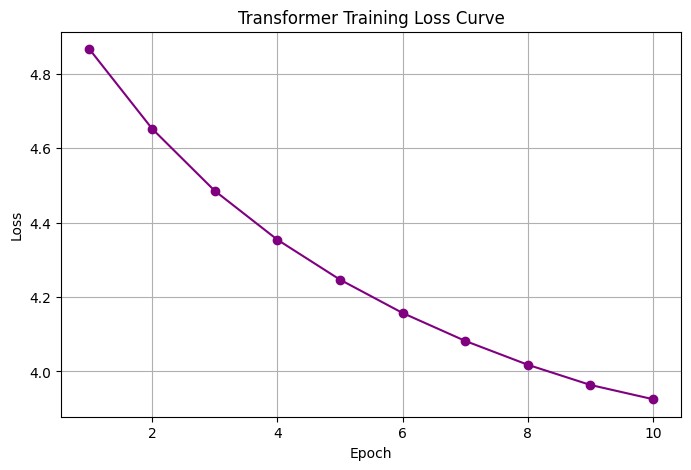

In [ ]:
import matplotlib.pyplot as plt

def translate_sentence(model, sentence, english_tokenizer, hindi_tokenizer, device, max_len=20):
    model.eval()
    # Tokenize English sentence
    tokens = english_tokenizer.texts_to_sequences([sentence], add_sos=False, add_eos=False)[0]
    # Pad to max_len
    if len(tokens) < max_len:
        tokens = tokens + [0] * (max_len - len(tokens))
    else:
        tokens = tokens[:max_len]

    src_tensor = torch.tensor([tokens], dtype=torch.long).to(device)

    #Start decoding sequence with <sos> (index 1)
    trg_indices = [hindi_tokenizer.word_index[hindi_tokenizer.sos_token]]

    with torch.no_grad():
        for i in range(max_len - 1):
            # Prepare target padded sequence where only already predicted tokens are present
            trg_padded = trg_indices + [0] * (max_len - len(trg_indices))
            trg_tensor = torch.tensor([trg_padded], dtype=torch.long).to(device)

            # Create an upper-triangular causal mask for target input so it doesn't look ahead
            # and ignores padding tokens.
            trg_mask = torch.triu(torch.ones((max_len, max_len)), diagonal=1).to(device) == 0
            trg_mask = trg_mask.unsqueeze(0).unsqueeze(1) # shape: [1, 1, max_len, max_len]

            # Forward pass
            output = model(src_tensor, trg_tensor, trg_mask=trg_mask)

            # Get next predicted token index at the specific position we are generating
            next_token = output[0, len(trg_indices) - 1].argmax(dim=-1).item()
            trg_indices.append(next_token)

            # Stop decoding if <eos> token predicted
            if next_token == hindi_tokenizer.word_index[hindi_tokenizer.eos_token]:
                break

    # Convert indices back to words
    translated_words = [hindi_tokenizer.index_word.get(idx, "<unk>") for idx in trg_indices]
    # Filter out special tokens
    cleaned_translation = [w for w in translated_words if w not in ["<pad>", "<sos>", "<eos>"]]
    return " ".join(cleaned_translation)

EPOCHS = 10
loss_history = []

print("Beginning Complete training of the Transformer...")
for epoch in range(1, EPOCHS + 1):
    avg_loss = train_epoch(model, dataloader, optimizer, criterion, device)
    loss_history.append(avg_loss)
    print(f"Epoch {epoch}/{EPOCHS} complete! Average Loss: {avg_loss:.4f}")

    demo_sentence = "Help!"
    translation = translate_sentence(model, demo_sentence, english_tokenizer, hindi_tokenizer, device)
    print(f"  Demo Translation -> English: '{demo_sentence}' | Predicted Hindi: '{translation}'\n")

# Plotting loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, EPOCHS + 1), loss_history, marker='o', color='purple')
plt.title("Transformer Training Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

In [ ]:
def predict_translation(sentence):
    translation = translate_sentence(
        model=model,
        sentence=sentence,
        english_tokenizer=english_tokenizer,
        hindi_tokenizer=hindi_tokenizer,
        device=device,
        max_len=MAX_LEN
    )
    return translation

test_sentences = [
    "Help!",
    "Go away!",
    "Come in.",
    "I forgot.",
    "Ohh my God!",
    "what's up",
    "how are you"
]

print("--- Model Translation Results ---")
for eng in test_sentences:
    pred_hindi = predict_translation(eng)
    print(f"English: {eng:<15} | Predicted Hindi: {pred_hindi}")

--- Model Translation Results ---
English: Help!           | Predicted Hindi: मदद
English: Go away!        | Predicted Hindi: जा कर बाहर जाना
English: Come in.        | Predicted Hindi: आ गया
English: I forgot.       | Predicted Hindi: मैं भूल गया
English: Ohh my God!     | Predicted Hindi: मेरी ईश्वर
English: what's up       | Predicted Hindi: क्या हो रहा है
English: how are you     | Predicted Hindi: तुम कैसे हो
